# Standards Integration: How ISO 26262, ISO 21448, ISO/SAE 21434 and ISO/PAS 8800 Work Together

**Module 08 · Standards, Regulation and Safety Case** · Notebook 1 of 4

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/08_Standards_Regulation_and_Safety_Case/01_standards_integration.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Intermediate | [HARA](../03_Functional_Safety_ISO26262/02_hara.ipynb), [SOTIF fundamentals](../04_SOTIF_ISO21448/01_sotif_fundamentals.ipynb), [TARA](../05_Cybersecurity_ISO21434/02_tara.ipynb), [AI safety standards](../06_AI_Safety_ISO_PAS_8800/01_ai_safety_standards.ipynb) | ISO 26262:2018, ISO 21448:2022, ISO/SAE 21434:2021, ISO/PAS 8800:2024, ISO/TS 5083:2025, UL 4600 (3rd ed.), ISO 34502:2022, ISO 34503:2023 |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

- Compare the scope, hazard source and key work products of the main AV safety and security documents
- Explain where the standards interface: shared item definition, HARA ↔ SOTIF hazard evaluation ↔ TARA impact rating, and safety–security co-engineering
- Decide which standard's cause analysis applies to a given hazard, without treating them as exclusive
- Carry out a combined HARA + SOTIF + TARA record for an AEB example, keeping ASIL, SOTIF acceptance and CAL side by side (they are not one scale)
- Identify the real coordination points between the disciplines (updates, degradation, logging, diagnostics) and document them traceably

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyBboxPatch
from scipy import stats
from IPython.display import display

# Okabe–Ito colour-blind-safe palette
OI = {"orange": "#E69F00", "sky": "#56B4E9", "green": "#009E73", "yellow": "#F0E442",
      "blue": "#0072B2", "vermillion": "#D55E00", "purple": "#CC79A7", "black": "#000000", "grey": "#999999"}
pd.set_option("display.max_colwidth", 90)
print("Setup complete")

Setup complete


## 1. The standards landscape in one table

Each document answers a different question. The three "process baseline" standards split the causes of harm:

- **ISO 26262:2018** (functional safety): *what if an E/E component malfunctions?* It covers random hardware faults **and** systematic faults (specification, design and software errors).
- **ISO 21448:2022** (SOTIF): *what if the intended functionality is insufficient, with no fault present?* It covers functional insufficiencies (specification insufficiencies and performance insufficiencies) revealed by **triggering conditions**, and reasonably foreseeable misuse.
- **ISO/SAE 21434:2021** (cybersecurity engineering): *what if someone deliberately manipulates the system?*

Three further documents sit on top of, or beside, that baseline:

- **ISO/PAS 8800:2024** (safety and AI) tailors the baseline to AI elements (mainly machine learning): data, AI safety requirements, AI-specific verification and the AI part of the assurance argument. It extends ISO 26262 and ISO 21448; it does not replace them.
- **ISO/TS 5083:2025** (safety for automated driving systems) and **UL 4600, 3rd ed. (2023)** work at the level of the whole ADS and its **safety case**.
- **ISO 34502:2022** (scenario-based safety evaluation framework) and **ISO 34503:2023** (ODD specification) supply the scenario and ODD vocabulary used by SOTIF validation and the ADS safety case.

The table below is the single comparison used throughout this module.

In [2]:
landscape = pd.DataFrame([
    {"Document": "ISO 26262:2018", "Type": "International Standard",
     "Scope": "12 parts; safety-related E/E systems in series-production road vehicles (mopeds excluded)",
     "Hazard source": "Malfunctioning behaviour: random hardware faults and systematic faults",
     "Key analyses / work products": "Item definition; HARA -> safety goals with ASIL; functional and technical safety concepts; "
                                     "hardware metrics (SPFM, LFM, PMHF); safety case; confirmation measures",
     "Main interfaces": "Item definition shared with 21448/21434; Part 2 asks for communication channels with cybersecurity"},
    {"Document": "ISO 21448:2022", "Type": "International Standard",
     "Scope": "Intended functionality that relies on sensing, perception and decision making (ADAS and ADS)",
     "Hazard source": "Functional insufficiencies + triggering conditions; reasonably foreseeable misuse (no fault needed)",
     "Key analyses / work products": "Hazard identification and evaluation; insufficiency and triggering-condition analysis; "
                                     "acceptance criteria and validation targets; evaluation of known/unknown scenarios (Areas 1-4); "
                                     "operation-phase monitoring",
     "Main interfaces": "Excludes E/E faults (-> 26262) and malicious attacks (-> 21434); evaluates hazards with severity and controllability"},
    {"Document": "ISO/SAE 21434:2021", "Type": "International Standard",
     "Scope": "Cybersecurity engineering of E/E systems of road vehicles over the whole lifecycle",
     "Hazard source": "Malicious manipulation: threat scenarios exploiting vulnerabilities",
     "Key analyses / work products": "Item definition; TARA (damage scenario -> impact rating; threat scenario -> attack path -> "
                                     "attack feasibility -> risk value 1-5 -> treatment); cybersecurity goals (optional CAL, Annex E, informative); "
                                     "cybersecurity concept; cybersecurity case; monitoring and incident response",
     "Main interfaces": "Safety impact category of damage scenarios uses ISO 26262 severity classes; supports UN R155 CSMS"},
    {"Document": "ISO/PAS 8800:2024", "Type": "Publicly Available Specification",
     "Scope": "AI elements (mainly ML) within safety-related E/E systems of road vehicles",
     "Hazard source": "AI output insufficiencies, systematic errors and random hardware faults affecting AI elements",
     "Key analyses / work products": "AI safety lifecycle; AI safety requirements; data-set requirements and data lifecycle; "
                                     "AI-specific safety analysis, verification and validation; assurance argument for the AI system; "
                                     "operation-phase monitoring",
     "Main interfaces": "Tailors 26262 and 21448 for AI components; its evidence feeds the item-level safety case"},
    {"Document": "ISO/TS 5083:2025", "Type": "Technical Specification",
     "Scope": "Safety of automated driving systems (SAE Level 3 and Level 4 features)",
     "Hazard source": "All sources of ADS risk; includes cybersecurity considerations",
     "Key analyses / work products": "Safety by design; verification and validation; post-deployment activities; ADS safety argument",
     "Main interfaces": "References the baseline standards and scenario-based testing; frames the ADS-level safety case"},
    {"Document": "UL 4600 (3rd ed., 2023)", "Type": "ANSI/UL standard",
     "Scope": "Safety case for autonomous products operating without human supervision",
     "Hazard source": "Technology-neutral: any hazard source",
     "Key analyses / work products": "Structured safety case (claims, arguments, evidence); safety performance indicators (SPIs); "
                                     "lifecycle and field-feedback requirements; independent assessment",
     "Main interfaces": "Goal-based; conformance to the ISO standards can be cited as evidence"},
    {"Document": "ISO 34502:2022", "Type": "International Standard",
     "Scope": "Scenario-based safety evaluation framework for ADS",
     "Hazard source": "Not a hazard taxonomy: test and evaluation perspective",
     "Key analyses / work products": "Identification of critical scenarios; derivation of test scenarios; evaluation process",
     "Main interfaces": "Feeds SOTIF V&V and the ADS safety case"},
    {"Document": "ISO 34503:2023", "Type": "International Standard",
     "Scope": "Specification of the operational design domain (ODD) for ADS",
     "Hazard source": "Not a hazard taxonomy: ODD definition",
     "Key analyses / work products": "Hierarchical ODD taxonomy: scenery, environmental conditions, dynamic elements",
     "Main interfaces": "Bounds the SOTIF specification; ODD attributes become operational situations in HARA"},
])
display(landscape.set_index("Document"))

# Text summary for screen readers (derived from the table)
print(f"{len(landscape)} documents compared. By type:")
for t, n in landscape["Type"].value_counts().items():
    print(f"  {t}: {n}")

,Type,Scope,Hazard source,Key analyses / work products,Main interfaces
Document,,,,,
ISO 26262:2018,International Standard,12 parts; safety-related E/E systems in series-production road vehicles (mopeds excluded),Malfunctioning behaviour: random hardware faults and systematic faults,Item definition; HARA -> safety goals with ASIL; functional and technical safety conce...,Item definition shared with 21448/21434; Part 2 asks for communication channels with c...
ISO 21448:2022,International Standard,"Intended functionality that relies on sensing, perception and decision making (ADAS an...",Functional insufficiencies + triggering conditions; reasonably foreseeable misuse (no ...,Hazard identification and evaluation; insufficiency and triggering-condition analysis;...,Excludes E/E faults (-> 26262) and malicious attacks (-> 21434); evaluates hazards wit...
ISO/SAE 21434:2021,International Standard,Cybersecurity engineering of E/E systems of road vehicles over the whole lifecycle,Malicious manipulation: threat scenarios exploiting vulnerabilities,Item definition; TARA (damage scenario -> impact rating; threat scenario -> attack pat...,Safety impact category of damage scenarios uses ISO 26262 severity classes; supports U...
ISO/PAS 8800:2024,Publicly Available Specification,AI elements (mainly ML) within safety-related E/E systems of road vehicles,"AI output insufficiencies, systematic errors and random hardware faults affecting AI e...",AI safety lifecycle; AI safety requirements; data-set requirements and data lifecycle;...,Tailors 26262 and 21448 for AI components; its evidence feeds the item-level safety case
ISO/TS 5083:2025,Technical Specification,Safety of automated driving systems (SAE Level 3 and Level 4 features),All sources of ADS risk; includes cybersecurity considerations,Safety by design; verification and validation; post-deployment activities; ADS safety ...,References the baseline standards and scenario-based testing; frames the ADS-level saf...
"UL 4600 (3rd ed., 2023)",ANSI/UL standard,Safety case for autonomous products operating without human supervision,Technology-neutral: any hazard source,"Structured safety case (claims, arguments, evidence); safety performance indicators (S...",Goal-based; conformance to the ISO standards can be cited as evidence
ISO 34502:2022,International Standard,Scenario-based safety evaluation framework for ADS,Not a hazard taxonomy: test and evaluation perspective,Identification of critical scenarios; derivation of test scenarios; evaluation process,Feeds SOTIF V&V and the ADS safety case
ISO 34503:2023,International Standard,Specification of the operational design domain (ODD) for ADS,Not a hazard taxonomy: ODD definition,"Hierarchical ODD taxonomy: scenery, environmental conditions, dynamic elements",Bounds the SOTIF specification; ODD attributes become operational situations in HARA


8 documents compared. By type:
  International Standard: 5
  Publicly Available Specification: 1
  Technical Specification: 1
  ANSI/UL standard: 1


### How the documents layer

The figure is a reading aid, not a normative hierarchy: regulations do not mandate any particular standard, but type-approval evidence is usually built from them (see [Notebook 2](02_regulation_and_type_approval.ipynb)).

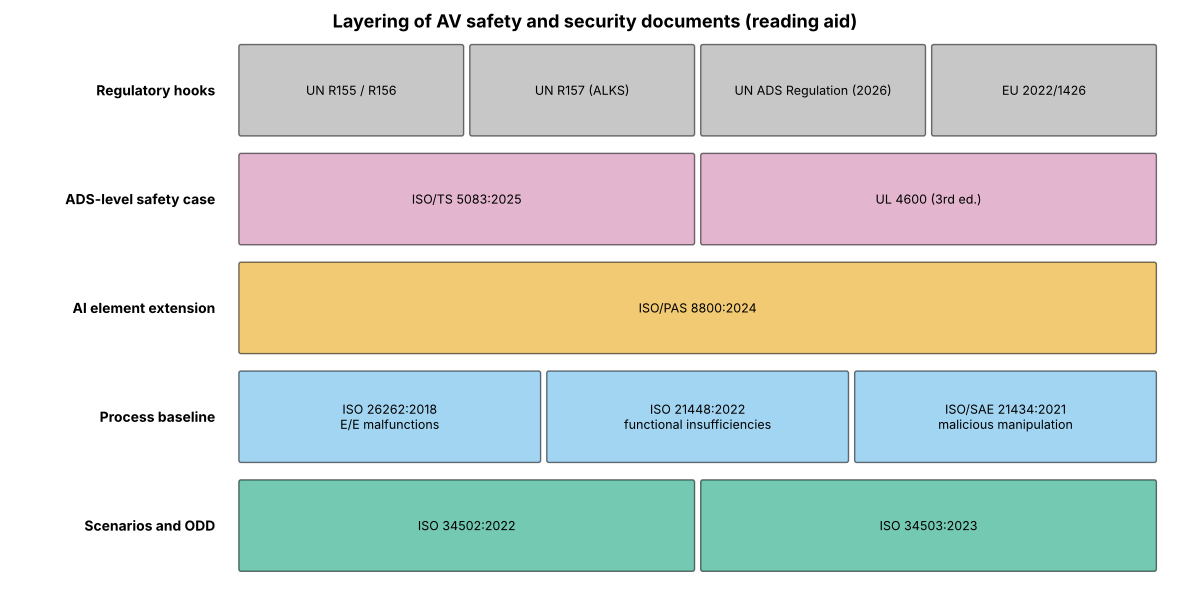

In [3]:
layers = [  # (row, label, boxes)
    (4, "Regulatory hooks", ["UN R155 / R156", "UN R157 (ALKS)", "UN ADS Regulation (2026)", "EU 2022/1426"]),
    (3, "ADS-level safety case", ["ISO/TS 5083:2025", "UL 4600 (3rd ed.)"]),
    (2, "AI element extension", ["ISO/PAS 8800:2024"]),
    (1, "Process baseline", ["ISO 26262:2018\nE/E malfunctions", "ISO 21448:2022\nfunctional insufficiencies", "ISO/SAE 21434:2021\nmalicious manipulation"]),
    (0, "Scenarios and ODD", ["ISO 34502:2022", "ISO 34503:2023"]),
]
colours = [OI["grey"], OI["purple"], OI["orange"], OI["sky"], OI["green"]]

fig, ax = plt.subplots(figsize=(12, 6))
for (row, label, boxes), col in zip(layers, colours):
    width = 9.0 / len(boxes)
    for i, b in enumerate(boxes):
        x = 2.2 + i * width
        ax.add_patch(FancyBboxPatch((x + 0.05, row + 0.1), width - 0.1, 0.8, boxstyle="round,pad=0.02",
                                    facecolor=col, alpha=0.55, edgecolor="black"))
        ax.text(x + width / 2, row + 0.5, b, ha="center", va="center", fontsize=9)
    ax.text(2.0, row + 0.5, label, ha="right", va="center", fontsize=10, fontweight="bold")
ax.set_xlim(0, 11.4)
ax.set_ylim(0, 5)
ax.axis("off")
ax.set_title("Layering of AV safety and security documents (reading aid)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

---

## 2. Which standard's analysis applies?

A useful first question is *what can cause this hazard?* The answer tells you which **cause analysis** you need. It does not split the hazard into separate silos:

- The **hazardous event** (for example "no braking for a pedestrian at 50 km/h") is rated at vehicle level in the HARA, independent of its cause.
- ISO 21448 evaluates the same hazards with severity and controllability. It does not assign an ASIL.
- In ISO/SAE 21434 the **safety** impact of a damage scenario is rated with the ISO 26262 severity classes.

The causes are then analysed with the matching method. Most real hazards have more than one cause, so more than one standard applies.

```
START: a potential hazardous behaviour has been identified
├─ Q1: Can it be caused by deliberate manipulation?            → ISO/SAE 21434 (TARA)
├─ Q2: Can it occur with no fault (insufficiency + trigger)?     → ISO 21448 (SOTIF)
├─ Q3: Can it be caused by an E/E malfunction (random/systematic)? → ISO 26262
├─ Q4: Is an ML element involved in Q2 or Q3?                    → also ISO/PAS 8800
└─ None selected → the hazard description is probably incomplete: re-examine it
All selected analyses run in parallel and share the item definition.
```

Typical couplings:
- A hardware fault (26262) can disable a security control (21434).
- A performance insufficiency (21448) can go undetected if the monitor that should catch it fails (26262).
- An attack (21434) can drive the system into a triggering condition (21448), for example sensor spoofing or adversarial patterns.

,Hazard,Standards,Count
0,Camera-based detector misses pedestrian in fog,"ISO 21448, ISO/PAS 8800",2
1,Radar sensor hardware failure,ISO 26262,1
2,Attacker spoofs GNSS signal (localisation error),ISO/SAE 21434,1
3,ML model misses dark-clothed cyclist at night,"ISO 21448, ISO/PAS 8800",2
4,"Software bug in brake calculation, during fog","ISO 21448, ISO 26262",2
5,Unspecified situation (description incomplete),No standard selected: re-examine the hazard,0


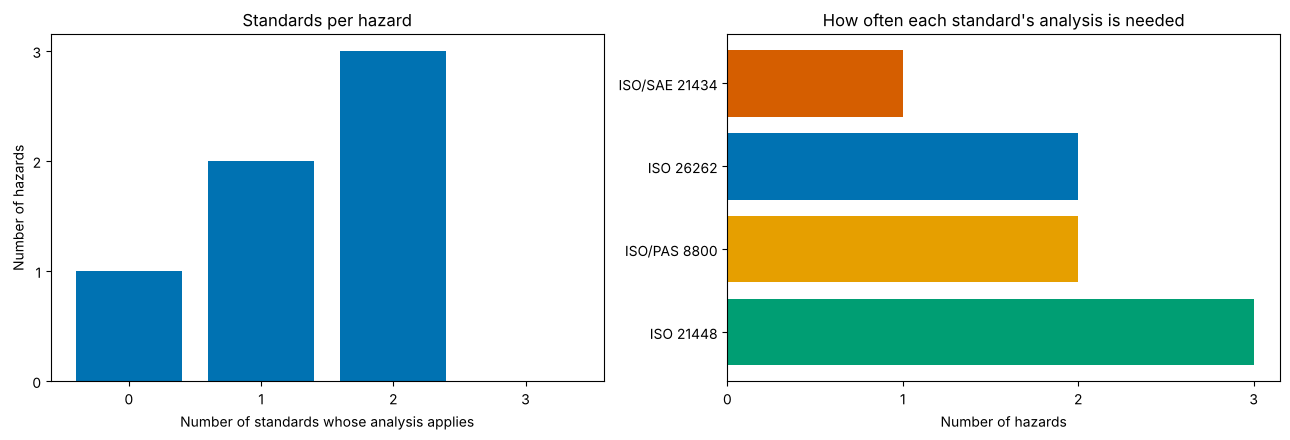

3 of 6 example hazards need more than one standard; 1 hazard(s) selected no standard and must be re-examined.
  ISO 21448: needed for 3 hazard(s)
  ISO/PAS 8800: needed for 2 hazard(s)
  ISO 26262: needed for 2 hazard(s)
  ISO/SAE 21434: needed for 1 hazard(s)


In [4]:
NO_STD = "No standard selected: re-examine the hazard"


def which_standards_apply(intentional_attack, functional_insufficiency, ee_malfunction, ml_element=False):
    """Return the standards whose cause analysis applies to a hazard (non-exclusive)."""
    standards = []
    if intentional_attack:
        standards.append("ISO/SAE 21434")
    if functional_insufficiency:
        standards.append("ISO 21448")
    if ee_malfunction:
        standards.append("ISO 26262")
    if ml_element and (functional_insufficiency or ee_malfunction):
        standards.append("ISO/PAS 8800")
    if not standards:
        standards.append(NO_STD)
    return standards


hazards = [
    {"name": "Camera-based detector misses pedestrian in fog",
     "intentional_attack": False, "functional_insufficiency": True, "ee_malfunction": False, "ml_element": True},
    {"name": "Radar sensor hardware failure",
     "intentional_attack": False, "functional_insufficiency": False, "ee_malfunction": True, "ml_element": False},
    {"name": "Attacker spoofs GNSS signal (localisation error)",
     "intentional_attack": True, "functional_insufficiency": False, "ee_malfunction": False, "ml_element": False},
    {"name": "ML model misses dark-clothed cyclist at night",
     "intentional_attack": False, "functional_insufficiency": True, "ee_malfunction": False, "ml_element": True},
    {"name": "Software bug in brake calculation, during fog",
     "intentional_attack": False, "functional_insufficiency": True, "ee_malfunction": True, "ml_element": False},
    {"name": "Unspecified situation (description incomplete)",
     "intentional_attack": False, "functional_insufficiency": False, "ee_malfunction": False, "ml_element": False},
]

rows = []
for h in hazards:
    applicable = which_standards_apply(h["intentional_attack"], h["functional_insufficiency"],
                                       h["ee_malfunction"], h["ml_element"])
    selected = [s for s in applicable if s != NO_STD]
    rows.append({"Hazard": h["name"], "Standards": ", ".join(applicable), "Count": len(selected)})
df_decision = pd.DataFrame(rows)
display(df_decision)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
counts = df_decision["Count"].value_counts().reindex(range(0, 4), fill_value=0)
ax1.bar(counts.index, counts.values, color=OI["blue"])
ax1.set_xlabel("Number of standards whose analysis applies")
ax1.set_ylabel("Number of hazards")
ax1.set_title("Standards per hazard")
ax1.set_xticks(range(0, 4))
ax1.yaxis.set_major_locator(plt.MaxNLocator(integer=True))

all_std = [s for h in hazards for s in which_standards_apply(h["intentional_attack"], h["functional_insufficiency"],
                                                              h["ee_malfunction"], h["ml_element"]) if s != NO_STD]
freq = pd.Series(all_std).value_counts()
std_colour = {"ISO 26262": OI["blue"], "ISO 21448": OI["green"], "ISO/SAE 21434": OI["vermillion"], "ISO/PAS 8800": OI["orange"]}
ax2.barh(freq.index, freq.values, color=[std_colour[s] for s in freq.index])
ax2.set_xlabel("Number of hazards")
ax2.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax2.set_title("How often each standard's analysis is needed")
plt.tight_layout()
plt.show()

# Text summary derived from the data
multi = int((df_decision["Count"] > 1).sum())
none = int((df_decision["Count"] == 0).sum())
print(f"{multi} of {len(df_decision)} example hazards need more than one standard; "
      f"{none} hazard(s) selected no standard and must be re-examined.")
for s, n in freq.items():
    print(f"  {s}: needed for {n} hazard(s)")

> **Note on the GNSS spoofing example:** the attack itself is analysed in the TARA. Its **safety consequence** (wrong localisation leading to a hazardous manoeuvre) is the hazardous event already rated in the HARA. The TARA damage scenario should reuse that rating, so that both analyses describe the same harm consistently.

---

## 3. Where the standards interface

| Interface | ISO 26262:2018 | ISO 21448:2022 | ISO/SAE 21434:2021 | ISO/PAS 8800:2024 |
|---|---|---|---|---|
| **System description** | Item definition (Part 3, Clause 5) | Specification and design, incl. ODD (Clause 5) | Item definition (Clause 9, concept phase) | AI system and AI element definition within the item |
| **Harm-oriented analysis** | HARA: S, E, C → ASIL (Part 3, Clause 6) | Hazard identification and evaluation with severity and controllability (Clause 6) | Damage scenarios → impact rating; safety impact uses ISO 26262 severity (Annex F, informative) | Uses the item-level HARA and SOTIF results |
| **Cause analysis** | FMEA/FTA/DFA of faults (Parts 4–6, 9) | Functional insufficiencies and triggering conditions (Clause 7) | Threat scenarios, attack paths, attack feasibility (Clause 15) | AI-specific safety analysis (data, model, deployment) |
| **Top-level objectives** | Safety goals with ASIL | Acceptance criteria and validation targets | Cybersecurity goals (optional CAL, Annex E) | AI safety requirements derived from the above |
| **Argument** | Safety case (Part 2) | Evaluation of the achievement of the SOTIF (Clause 12) | Cybersecurity case (Clause 6) | Assurance argument for the AI system |
| **Operation** | Production, operation, service (Part 7); change management (Part 8, Clause 8) | Operation-phase activities, field monitoring (Clause 13) | Continual activities (Clause 8); operations and maintenance (Clause 13) | Operation-phase monitoring of AI performance |

**Co-engineering.** ISO 26262-2 asks organisations to keep communication channels open between functional safety and cybersecurity. Its informative Annex E illustrates how the two interact. ISO/SAE 21434 Clause 5 likewise asks for communication with related disciplines such as functional safety. In practice this means:

- a **shared item definition** and ODD;
- **consistent harm ratings**, so that HARA severity and TARA safety impact describe the same hazardous event;
- **joint review** wherever a safety mechanism and a security control protect the same signal, for example end-to-end protection (CRC, counter) versus message authentication codes.

---

## 4. A combined HARA + SOTIF + TARA record

The class below keeps **each standard's own result** for a hazard and lists the coordination actions that follow from them. It deliberately does **not** compute an "integrated severity":

- An **ASIL** is the integrity requirement of a safety goal (ISO 26262-3 Table 4).
- A **SOTIF acceptance** result says whether the residual risk meets an acceptance criterion or validation target (ISO 21448).
- A **risk value** (1–5) ranks a threat scenario. A **CAL** (1–4) sets the rigour of cybersecurity assurance for a goal (ISO/SAE 21434 Annexes H and E, both informative).

No standard defines a common scale for these, so taking a maximum across them is meaningless.

The tables below are copied from the repository toolkit, so the notebook stays self-contained. The same functions are available as `avsafety.iso26262.determine_asil`, `avsafety.iso21434.determine_cal` and `avsafety.iso21434.risk_value`; see the repo `avsafety/`.

In [5]:
# ISO 26262-3:2018 Table 4. ASIL_TABLE[S][E] -> (C1, C2, C3)
ASIL_TABLE = {
    "S1": {"E1": ("QM", "QM", "QM"), "E2": ("QM", "QM", "QM"), "E3": ("QM", "QM", "A"), "E4": ("QM", "A", "B")},
    "S2": {"E1": ("QM", "QM", "QM"), "E2": ("QM", "QM", "A"), "E3": ("QM", "A", "B"), "E4": ("A", "B", "C")},
    "S3": {"E1": ("QM", "QM", "A"), "E2": ("QM", "A", "B"), "E3": ("A", "B", "C"), "E4": ("B", "C", "D")},
}


def determine_asil(s, e, c):
    """ASIL from ISO 26262-3:2018 Table 4; S0, E0 or C0 give QM."""
    if s == "S0" or e == "E0" or c == "C0":
        return "QM"
    return ASIL_TABLE[s][e][int(c[1]) - 1]


# ISO/SAE 21434:2021 Annex F (informative): safety impact rating uses ISO 26262 severity classes
SEVERITY_TO_SAFETY_IMPACT = {"S0": "Negligible", "S1": "Moderate", "S2": "Major", "S3": "Severe"}

# Attack potential (Annex G.2, values from ISO/IEC 18045) -> attack feasibility
ELAPSED_TIME = {"<=1 day": 0, "<=1 week": 1, "<=1 month": 4, "<=6 months": 17, ">6 months": 19}
EXPERTISE = {"layman": 0, "proficient": 3, "expert": 6, "multiple experts": 8}
KNOWLEDGE = {"public": 0, "restricted": 3, "confidential": 7, "strictly confidential": 11}
WINDOW = {"unlimited": 0, "easy": 1, "moderate": 4, "difficult": 10}
EQUIPMENT = {"standard": 0, "specialized": 4, "bespoke": 7, "multiple bespoke": 9}


def feasibility_from_potential(p):
    return "High" if p <= 13 else "Medium" if p <= 19 else "Low" if p <= 24 else "Very Low"


# Example risk matrix (Annex H, informative): impact x feasibility -> risk value 1..5
RISK_MATRIX = {
    "Severe": {"Very Low": 2, "Low": 3, "Medium": 4, "High": 5},
    "Major": {"Very Low": 1, "Low": 2, "Medium": 3, "High": 4},
    "Moderate": {"Very Low": 1, "Low": 2, "Medium": 2, "High": 3},
    "Negligible": {"Very Low": 1, "Low": 1, "Medium": 1, "High": 1},
}

# Example CAL determination (Annex E, informative): impact x ATTACK VECTOR (not feasibility)
CAL_TABLE = {
    "Severe": {"Physical": 2, "Local": 3, "Adjacent": 4, "Network": 4},
    "Major": {"Physical": 1, "Local": 2, "Adjacent": 3, "Network": 4},
    "Moderate": {"Physical": 1, "Local": 1, "Adjacent": 2, "Network": 3},
}


def determine_cal(impact, attack_vector):
    return None if impact == "Negligible" else CAL_TABLE[impact][attack_vector]


# Show the ASIL table as it appears in ISO 26262-3 Table 4
asil_view = pd.DataFrame({(s, e): ASIL_TABLE[s][e] for s in ASIL_TABLE for e in ASIL_TABLE[s]},
                         index=["C1", "C2", "C3"]).T
display(asil_view)

# Optional cross-check against the repository toolkit (skipped when avsafety is not installed, e.g. on Colab)
try:
    from avsafety import iso26262, iso21434
    ok_asil = all(determine_asil(s, e, c) == iso26262.determine_asil(s, e, c)
                  for s in ["S0", "S1", "S2", "S3"] for e in ["E0", "E1", "E2", "E3", "E4"] for c in ["C0", "C1", "C2", "C3"])
    ok_cal = all(determine_cal(i, v) == iso21434.determine_cal(i, v)
                 for i in ["Negligible", "Moderate", "Major", "Severe"] for v in ["Physical", "Local", "Adjacent", "Network"])
    print(f"Consistent with avsafety: ASIL table {ok_asil}, CAL table {ok_cal}")
except ImportError:
    print("avsafety not installed; cross-check skipped")

C1  C2  C3
S1 E1  QM  QM  QM
   E2  QM  QM  QM
   E3  QM  QM   A
   E4  QM   A   B
S2 E1  QM  QM  QM
   E2  QM  QM   A
   E3  QM   A   B
   E4   A   B   C
S3 E1  QM  QM   A
   E2  QM   A   B
   E3   A   B   C
   E4   B   C   D

Consistent with avsafety: ASIL table True, CAL table True


In [6]:
def sotif_evaluation(hazardous_events, exposure_h, target_rate_per_h, confidence=0.95):
    """Compare a one-sided Poisson upper bound on the hazardous-behaviour rate with a validation target.

    ISO 21448 asks for acceptance criteria and validation targets but leaves their values to the developer.
    """
    upper = stats.chi2.ppf(confidence, 2 * (hazardous_events + 1)) / 2 / exposure_h
    return {"events": hazardous_events, "exposure_h": exposure_h, "upper_bound_per_h": upper,
            "target_per_h": target_rate_per_h, "met": bool(upper <= target_rate_per_h)}


class HazardRecord:
    """Keeps HARA, SOTIF, TARA (and PAS 8800 applicability) results side by side for one hazard."""

    def __init__(self, hazard_id, description, ml_element=False):
        self.id, self.description, self.ml_element = hazard_id, description, ml_element
        self.hara = self.sotif = self.tara = None

    def add_hara(self, s, e, c):
        self.hara = {"S": s, "E": e, "C": c, "ASIL": determine_asil(s, e, c)}

    def add_sotif(self, events, exposure_h, target_per_h, triggering_condition):
        self.sotif = sotif_evaluation(events, exposure_h, target_per_h)
        self.sotif["triggering_condition"] = triggering_condition

    def add_tara(self, attack_vector, elapsed, expertise, knowledge, window, equipment, severity_class):
        impact = SEVERITY_TO_SAFETY_IMPACT[severity_class]   # reuse the HARA severity of the same harm
        potential = (ELAPSED_TIME[elapsed] + EXPERTISE[expertise] + KNOWLEDGE[knowledge]
                     + WINDOW[window] + EQUIPMENT[equipment])
        feas = feasibility_from_potential(potential)
        self.tara = {"impact (safety)": impact, "attack potential": potential, "feasibility": feas,
                     "risk value": RISK_MATRIX[impact][feas], "attack vector": attack_vector,
                     "CAL": determine_cal(impact, attack_vector)}

    def standards(self):
        out = []
        if self.hara: out.append("ISO 26262")
        if self.sotif: out.append("ISO 21448")
        if self.tara: out.append("ISO/SAE 21434")
        if self.ml_element: out.append("ISO/PAS 8800")
        return out

    def coordination_actions(self):
        """Actions derived from the per-standard results (no cross-standard 'max')."""
        acts = []
        if self.hara and self.tara:
            acts.append("TARA safety impact taken from HARA severity "
                        f"({self.hara['S']} -> {self.tara['impact (safety)']}): keep both ratings consistent")
            if self.hara["ASIL"] in ("C", "D") and (self.tara["CAL"] or 0) >= 3:
                acts.append("Security control protects an ASIL C/D safety goal: joint review of safety mechanisms "
                            "and security controls on the same signals")
        if self.tara and self.tara["risk value"] >= 4:
            acts.append(f"Risk value {self.tara['risk value']}: risk treatment decision required (reduce, avoid, share or retain with rationale)")
        if self.sotif and not self.sotif["met"]:
            acts.append("Validation target not demonstrated: more evidence or functional modification (ISO 21448 Clause 8)")
        if self.ml_element:
            acts.append("ML element: apply the ISO/PAS 8800 AI safety lifecycle (data requirements, AI safety requirements, monitoring)")
        return acts or ["No cross-standard coordination action identified"]

    def report(self):
        print("=" * 90)
        print(f"{self.id}: {self.description}")
        print("=" * 90)
        if self.hara:
            print(f"ISO 26262 HARA : {self.hara['S']} {self.hara['E']} {self.hara['C']} -> ASIL {self.hara['ASIL']}")
        if self.sotif:
            s = self.sotif
            print(f"ISO 21448      : trigger '{s['triggering_condition']}'; {s['events']} event(s) in {s['exposure_h']:.0f} h; "
                  f"95% upper bound {s['upper_bound_per_h']:.1e}/h vs target {s['target_per_h']:.0e}/h -> "
                  f"{'met' if s['met'] else 'NOT met'}")
        if self.tara:
            t = self.tara
            print(f"ISO/SAE 21434  : impact {t['impact (safety)']}, attack potential {t['attack potential']} -> feasibility "
                  f"{t['feasibility']}, risk value {t['risk value']}; vector {t['attack vector']} -> CAL {t['CAL']}")
        if self.ml_element:
            print("ISO/PAS 8800   : applies (ML element involved)")
        print("Coordination actions:")
        for a in self.coordination_actions():
            print(f"  - {a}")

### Worked example: automatic emergency braking (AEB)

> **Illustrative data:** values below are synthetic, chosen for teaching; they are not measurements. The ratings (S, E, C, attack-potential factors, exposure hours, validation targets) are example judgements for a generic AEB system, not results for any real product.

Configuration (illustrative): front camera with a DNN detector, 77 GHz radar, sensor fusion, brake ECU on a CAN bus.

| ID | Hazard | Causes considered |
|---|---|---|
| H1 | Unintended emergency braking at motorway speed | E/E fault in the brake ECU |
| H2 | No braking for a pedestrian in dense fog | DNN performance insufficiency (no fault) |
| H3 | Phantom obstacle injected by radar spoofing, causing unintended braking | Attack via the RF channel |
| H4 | Spurious brake request on CAN while the camera is degraded by heavy rain | Message injection, corrupted-frame handling, rain trigger |

In [7]:
h1 = HazardRecord("H1", "Unintended emergency braking at motorway speed (brake ECU fault)")
h1.add_hara("S3", "E4", "C3")   # as HE-03 in the HARA (Module 03, Notebook 02)

h2 = HazardRecord("H2", "No braking for pedestrian in dense fog (DNN insufficiency)", ml_element=True)
h2.add_hara("S3", "E2", "C2")   # same hazardous event as HE-01 in the HARA, rated once at vehicle level; fog is the triggering condition
h2.add_sotif(events=3, exposure_h=2.0e4, target_per_h=1e-4, triggering_condition="dense fog, visibility < 50 m")

h3 = HazardRecord("H3", "Radar spoofing creates phantom obstacle -> unintended braking")
h3.add_hara("S3", "E4", "C3")   # same hazardous event as H1
h3.add_tara("Adjacent", "<=1 month", "expert", "restricted", "moderate", "bespoke", severity_class="S3")

h4 = HazardRecord("H4", "Injected brake request on CAN while camera degraded by heavy rain", ml_element=True)
h4.add_hara("S3", "E4", "C3")   # unintended braking, as H1
h4.add_sotif(events=1, exposure_h=5.0e4, target_per_h=1e-4, triggering_condition="heavy rain on windscreen")
h4.add_tara("Local", "<=1 week", "proficient", "restricted", "easy", "standard", severity_class="S3")

aeb = [h1, h2, h3, h4]
for h in aeb:
    h.report()
    print()

H1: Unintended emergency braking at motorway speed (brake ECU fault)
ISO 26262 HARA : S3 E4 C3 -> ASIL D
Coordination actions:
  - No cross-standard coordination action identified

H2: No braking for pedestrian in dense fog (DNN insufficiency)
ISO 26262 HARA : S3 E2 C2 -> ASIL A
ISO 21448      : trigger 'dense fog, visibility < 50 m'; 3 event(s) in 20000 h; 95% upper bound 3.9e-04/h vs target 1e-04/h -> NOT met
ISO/PAS 8800   : applies (ML element involved)
Coordination actions:
  - Validation target not demonstrated: more evidence or functional modification (ISO 21448 Clause 8)
  - ML element: apply the ISO/PAS 8800 AI safety lifecycle (data requirements, AI safety requirements, monitoring)

H3: Radar spoofing creates phantom obstacle -> unintended braking
ISO 26262 HARA : S3 E4 C3 -> ASIL D
ISO/SAE 21434  : impact Severe, attack potential 24 -> feasibility Low, risk value 3; vector Adjacent -> CAL 4
Coordination actions:
  - TARA safety impact taken from HARA severity (S3 -> Severe):

,Hazard,Standards,ASIL (26262),Target met? (21448),Risk value (21434),CAL (21434),Coordination actions
0,H1,ISO 26262,D,-,-,-,1
1,H2,"ISO 26262, ISO 21448, ISO/PAS 8800",A,no,-,-,2
2,H3,"ISO 26262, ISO/SAE 21434",D,-,3,4,2
3,H4,"ISO 26262, ISO 21448, ISO/SAE 21434, ISO/PAS 8800",D,yes,5,3,4


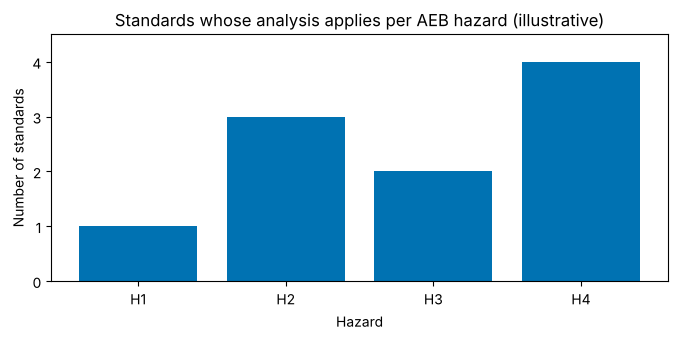

3 of 4 AEB hazards (75%) are analysed under more than one standard.
Results are reported per standard; ASIL, SOTIF acceptance, risk value and CAL are not merged into one score.


In [8]:
summary = pd.DataFrame([{
    "Hazard": h.id,
    "Standards": ", ".join(h.standards()),
    "ASIL (26262)": h.hara["ASIL"] if h.hara else "-",
    "Target met? (21448)": ("yes" if h.sotif["met"] else "no") if h.sotif else "-",
    "Risk value (21434)": h.tara["risk value"] if h.tara else "-",
    "CAL (21434)": h.tara["CAL"] if h.tara else "-",
    "Coordination actions": len(h.coordination_actions()),
} for h in aeb])
display(summary)

n_std = [len(h.standards()) for h in aeb]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar([h.id for h in aeb], n_std, color=OI["blue"])
ax.set_ylabel("Number of standards")
ax.set_xlabel("Hazard")
ax.set_ylim(0, 4.5)
ax.set_title("Standards whose analysis applies per AEB hazard (illustrative)")
plt.tight_layout()
plt.show()

multi = sum(n > 1 for n in n_std)
print(f"{multi} of {len(aeb)} AEB hazards ({100 * multi / len(aeb):.0f}%) are analysed under more than one standard.")
print("Results are reported per standard; ASIL, SOTIF acceptance, risk value and CAL are not merged into one score.")

---

## 5. Real coordination points between the disciplines

The standards rarely give *contradictory* requirements. Tensions arise where they act on the **same artefact** for different reasons, as the table below shows. It replaces an earlier version of this notebook that attributed fixed coverage percentages or "fail-safe only" positions to the standards. They contain no such requirements:

- ISO 26262-6 recommends structural coverage metrics (statement, branch, MC/DC) by ASIL without fixed percentages.
- ISO 26262 defines safe states and emergency operation; it does not prefer fail-safe over fail-operational.

In [9]:
coordination = pd.DataFrame([
    {"Topic": "Software updates",
     "ISO 26262": "Change management and impact analysis (Part 8, Clause 8)",
     "ISO 21448": "Updates to fix insufficiencies found in field monitoring (Clause 13)",
     "ISO/SAE 21434 / regulation": "Vulnerability-driven patches (Clauses 8, 13); UN R156 SUMS and ISO 24089:2023",
     "Coordination approach": "One update process: impact analysis covers safety, SOTIF and security; R156 type-approval impact assessed"},
    {"Topic": "Degradation and fallback",
     "ISO 26262": "Safe states, emergency operation, fault-tolerant time intervals",
     "ISO 21448": "Residual-risk acceptance incl. behaviour at ODD boundary",
     "ISO/SAE 21434 / regulation": "Incident response; detected intrusion may trigger restricted mode",
     "Coordination approach": "Jointly specified degradation modes; check that a security reaction cannot create a hazard"},
    {"Topic": "Data logging",
     "ISO 26262": "Fault memory / diagnostic data",
     "ISO 21448": "Field monitoring of triggering conditions and near misses",
     "ISO/SAE 21434 / regulation": "Integrity and confidentiality of logs; GDPR; DSSAD (UN R157) and EDR",
     "Coordination approach": "Data minimisation plan that still meets monitoring needs; protected, tamper-evident logs"},
    {"Topic": "Signal protection",
     "ISO 26262": "End-to-end protection (CRC, counter, timeout) against corruption",
     "ISO 21448": "Plausibility checks against sensor insufficiencies",
     "ISO/SAE 21434 / regulation": "Message authentication (MAC, freshness) against injection",
     "Coordination approach": "Common protection profile per signal; timing budget shared between E2E and MAC"},
    {"Topic": "Diagnostic access",
     "ISO 26262": "Service and diagnostic functions must stay usable",
     "ISO 21448": "-",
     "ISO/SAE 21434 / regulation": "Authenticated diagnostics; R155 Annex 5 threats via external interfaces",
     "Coordination approach": "Authenticated diagnostic sessions with a safe-state precondition"},
])

for i, row in coordination.iterrows():
    print(f"[{i + 1}] {row['Topic']}")
    for col in ["ISO 26262", "ISO 21448", "ISO/SAE 21434 / regulation", "Coordination approach"]:
        print(f"    {col:<28}: {row[col]}")

[1] Software updates
    ISO 26262                   : Change management and impact analysis (Part 8, Clause 8)
    ISO 21448                   : Updates to fix insufficiencies found in field monitoring (Clause 13)
    ISO/SAE 21434 / regulation  : Vulnerability-driven patches (Clauses 8, 13); UN R156 SUMS and ISO 24089:2023
    Coordination approach       : One update process: impact analysis covers safety, SOTIF and security; R156 type-approval impact assessed
[2] Degradation and fallback
    ISO 26262                   : Safe states, emergency operation, fault-tolerant time intervals
    ISO 21448                   : Residual-risk acceptance incl. behaviour at ODD boundary
    ISO/SAE 21434 / regulation  : Incident response; detected intrusion may trigger restricted mode
    Coordination approach       : Jointly specified degradation modes; check that a security reaction cannot create a hazard
[3] Data logging
    ISO 26262                   : Fault memory / diagnostic data
    ISO 

**Resolution process.** Avoid a fixed rule such as "safety before security": security is often a precondition for safety. Resolve tensions by joint safety–security analysis at the shared interfaces, prioritised by risk. Record the rationale and approvals in both the safety case and the cybersecurity case.

---

## 6. Documentation and traceability

| Work product | ISO 26262 | ISO 21448 | ISO/SAE 21434 | ISO/PAS 8800 |
|---|---|---|---|---|
| Hazard / threat analysis | HARA | Hazard evaluation; insufficiency and triggering-condition analysis | TARA | AI-specific safety analysis |
| Top-level objectives | Safety goals (ASIL) | Acceptance criteria, validation targets | Cybersecurity goals (optional CAL) | AI safety requirements |
| Requirements | Functional and technical safety requirements | Functional modifications | Cybersecurity requirements | Data and model requirements |
| Architecture | Safety architecture | Specification and design (incl. ODD) | Cybersecurity concept / architecture | AI element architecture |
| V&V | Safety verification and validation | Known/unknown scenario evaluation | Cybersecurity verification and validation (Clause 11) | AI verification and validation |
| Argument | Safety case | SOTIF achievement evaluation (Clause 12) | Cybersecurity case | AI assurance argument |

All four arguments feed one product-level case. Building such an argument in Goal Structuring Notation (GSN), including how cybersecurity evidence enters the AI safety argument, is the subject of [Notebook 4: Safety case with GSN](04_safety_case_gsn.ipynb).

**Traceability requirements:**
1. **Bidirectional:** trace up from code and data to hazards, and down from hazards to tests.
2. **Cross-standard:** link the same hazardous event across the HARA, the SOTIF analysis and the TARA.
3. **Version-controlled:** keep the history of every item.
4. **Tool-supported:** manual traceability does not scale.

,Hazard ID,Standards,Goal,Requirements,Tests,Status
0,H1,26262,SG-01 (ASIL D),"FSR-01, FSR-02, TSR-05","TC-01, TC-02",Complete
1,H2,"21448, 8800",SOTIF-AC-02,"FM-03, DATA-07","SC-11, SC-12",In progress
2,H3,"26262, 21434",CSG-03 (CAL 4),CSR-04,PT-01,Complete
3,H4,"26262, 21448, 21434, 8800","SG-01, CSG-04","TSR-06, CSR-05, FM-04","TC-07, PT-02, SC-15",Under review


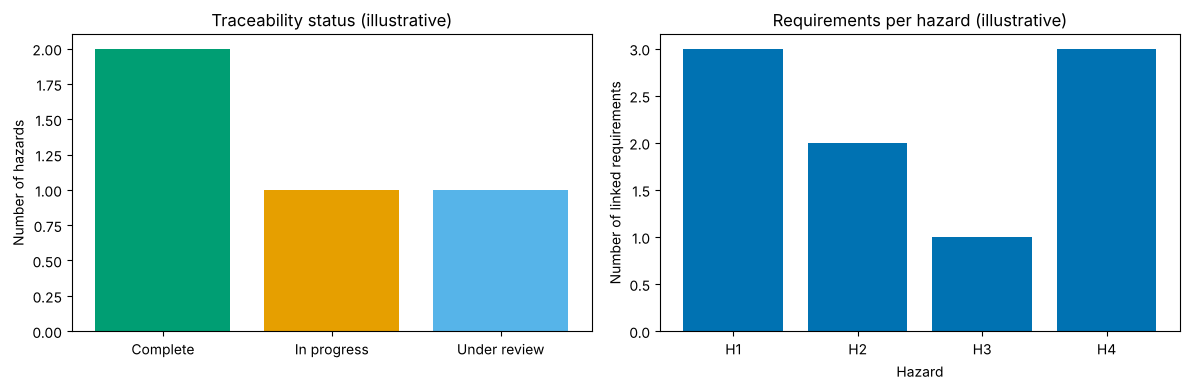

Hazards: 4; linked requirements: 9; complete: 2 (50%)


In [10]:
# Illustrative data: identifiers and statuses are synthetic, chosen for teaching.
traceability = pd.DataFrame([
    {"Hazard ID": "H1", "Standards": "26262", "Goal": "SG-01 (ASIL D)", "Requirements": "FSR-01, FSR-02, TSR-05",
     "Tests": "TC-01, TC-02", "Status": "Complete"},
    {"Hazard ID": "H2", "Standards": "21448, 8800", "Goal": "SOTIF-AC-02", "Requirements": "FM-03, DATA-07",
     "Tests": "SC-11, SC-12", "Status": "In progress"},
    {"Hazard ID": "H3", "Standards": "26262, 21434", "Goal": "CSG-03 (CAL 4)", "Requirements": "CSR-04",
     "Tests": "PT-01", "Status": "Complete"},
    {"Hazard ID": "H4", "Standards": "26262, 21448, 21434, 8800", "Goal": "SG-01, CSG-04", "Requirements": "TSR-06, CSR-05, FM-04",
     "Tests": "TC-07, PT-02, SC-15", "Status": "Under review"},
])
display(traceability)

req_counts = traceability["Requirements"].str.split(", ").apply(len)
status = traceability["Status"].value_counts()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.bar(status.index, status.values, color=[OI["green"], OI["orange"], OI["sky"]][:len(status)])
ax1.set_ylabel("Number of hazards")
ax1.set_title("Traceability status (illustrative)")
ax2.bar(traceability["Hazard ID"], req_counts, color=OI["blue"])
ax2.set_xlabel("Hazard")
ax2.set_ylabel("Number of linked requirements")
ax2.set_title("Requirements per hazard (illustrative)")
plt.tight_layout()
plt.show()

complete = int((traceability["Status"] == "Complete").sum())
print(f"Hazards: {len(traceability)}; linked requirements: {int(req_counts.sum())}; "
      f"complete: {complete} ({100 * complete / len(traceability):.0f}%)")

---

## 7. Tool chain for multi-standard work

The tools listed are examples of each category, not endorsements:

| Tool category | Purpose | Examples | Typically supports |
|---|---|---|---|
| Requirements and traceability | Requirements, trace links, baselines | IBM DOORS Next, Siemens Polarion, Jama Connect, PTC Codebeamer | All |
| Safety and security analysis | HARA, FMEA/FTA, SOTIF analysis, TARA | Ansys medini analyze, other model-based analysis tools | 26262, 21448, 21434 |
| Model-based design | Architecture and controller models | MATLAB/Simulink, SCADE | 26262 |
| Static analysis | Coding-guideline and defect checks | Polyspace, Coverity, Astrée | 26262, 21434 |
| Dynamic / HIL testing | Unit, integration, HIL tests | VectorCAST, TPT, CANoe, dSPACE | All |
| Scenario-based simulation | Scenario and ODD testing | CARLA, esmini (ASAM OpenSCENARIO), IPG CarMaker | 21448, 34502 |
| Security testing | Fuzzing, penetration testing | Protocol fuzzers, CAN tooling, penetration-test frameworks | 21434 |

Two practices make the tool chain work. A single requirements and traceability hub is the reference for every standard. Its change-impact analysis must reach every analysis: HARA, SOTIF, TARA and the AI data sets.

---

## 8. Good practice for an integrated safety case

1. **Start with a joint hazard picture.** Map every hazardous event once and link the cause analyses (26262, 21448, 21434, 8800) to it.
2. **Keep ratings separate but consistent.** Do not merge ASIL, SOTIF acceptance and CAL into one score. Make sure the TARA safety impact matches the HARA severity of the same harm.
3. **Document decisions.** Assessors and approval authorities will ask why each trade-off was made.
4. **Automate traceability.** Manual spreadsheets drift out of date.
5. **Test combined conditions.** Examples are an attack during a triggering condition, or a fault while degraded by weather.
6. **Co-engineer early.** Safety, SOTIF, security and ML teams should share reviews and not hand over at the end.
7. **Plan for operation.** Field monitoring (21448 Clause 13), vulnerability management (21434 Clause 8) and updates (UN R156) continue for the vehicle's life.

---

## Key takeaways

- ISO 26262 covers **E/E malfunctions** (random hardware and systematic faults). ISO 21448 covers **functional insufficiencies** under triggering conditions and foreseeable misuse. ISO/SAE 21434 covers **malicious manipulation**. ISO/PAS 8800 extends 26262 and 21448 to **ML elements**. ISO/TS 5083 and UL 4600 frame the **ADS-level safety case**. ISO 34502 and 34503 provide **scenario and ODD** foundations.
- The standards meet at a shared item definition, consistent harm ratings (HARA severity ↔ SOTIF evaluation ↔ TARA safety impact) and joint review of shared signals and processes.
- ASIL, SOTIF acceptance, risk value and CAL answer different questions. Report them side by side and never take a "maximum" across them.
- CAL is determined from impact and **attack vector** (Annex E, informative), not from attack feasibility.
- Real tensions concern updates, degradation, logging, signal protection and diagnostics. Resolve them by joint analysis and recorded rationale, not by a fixed discipline ranking.

## Self-assessment

1. A radar spoofing attack causes unintended braking. Which analyses apply, and how should the TARA impact rating relate to the HARA?
2. Why is it wrong to compute `max(ASIL, CAL)`?
3. What two inputs determine a CAL in the ISO/SAE 21434 Annex E example?
4. Give two interfaces where ISO/PAS 8800 adds to ISO 21448 for a DNN-based pedestrian detector.
5. Where do ISO/TS 5083 and UL 4600 sit relative to the three baseline standards?

<details>
<summary>Answers</summary>

1. TARA (ISO/SAE 21434) analyses the attack. HARA (ISO 26262) rates the hazardous event "unintended braking". The SOTIF analysis applies if the phantom obstacle exploits a perception insufficiency. The TARA safety impact should reuse the HARA severity of the same harm, e.g. S3 → Severe (21434 Annex F).
2. An ASIL is an integrity requirement for a safety goal, and a CAL is an assurance-rigour level for a cybersecurity goal. They are defined on different bases, and no standard defines a common scale.
3. The impact rating and the attack vector (physical, local, adjacent, network).
4. Any two of: data-set requirements (coverage of the ODD and triggering conditions, label quality), AI safety requirements on the model, AI-specific verification (robustness, uncertainty), operation-phase monitoring of AI performance, and the AI part of the assurance argument.
5. Above them: they address the safety argument for the whole ADS and use evidence produced under 26262, 21448 and 21434 (and 8800 for ML elements).
</details>

## References

- ISO 26262:2018, *Road vehicles — Functional safety* (Parts 1–12). https://www.iso.org/standard/68383.html (Part 1)
- ISO 21448:2022, *Road vehicles — Safety of the intended functionality*. https://www.iso.org/standard/77490.html
- ISO/SAE 21434:2021, *Road vehicles — Cybersecurity engineering*. https://www.iso.org/standard/70918.html
- ISO/PAS 8800:2024, *Road vehicles — Safety and artificial intelligence*. https://www.iso.org/standard/83303.html
- ISO/TS 5083:2025, *Road vehicles — Safety for automated driving systems — Design, verification and validation*. https://www.iso.org/standard/81920.html
- ISO 34502:2022, *Road vehicles — Test scenarios for automated driving systems — Scenario based safety evaluation framework*.
- ISO 34503:2023, *Road vehicles — Test scenarios for automated driving systems — Specification for operational design domain*.
- UL 4600, *Standard for Safety for the Evaluation of Autonomous Products*, 3rd ed. (March 2023). https://www.ul.com/news/ul-4600-edition-3-updates-incorporate-autonomous-trucking
- ISO/IEC 18045:2022, *Methodology for IT security evaluation* (source of the attack-potential factors).
- Patel, M., Jung, R. (2026). Integrating Cybersecurity Into the AI Safety Assurance Argument: A GSN Pattern for AI-Based Perception Components in Highly Automated Driving. In *Computer Safety, Reliability, and Security. SAFECOMP 2026 Workshops*, LNCS, pp. 763–779. Springer. https://doi.org/10.1007/978-3-032-35506-5_55

## Further practice

- Companion notebook: [Standards Summary](https://github.com/milinpatel07/AI-Perception-Safety-Workshop/blob/main/notebooks/13_standards_summary.ipynb) in the author's *AI Perception Safety Workshop* repository.

---
**Navigation:** ← [Module 08 overview](README.md) · [Module index](README.md) · [Regulation and type approval](02_regulation_and_type_approval.ipynb) →